<a href="https://colab.research.google.com/github/Elizabeth2061/MN_Lab_PRUDKA/blob/main/%D0%9B%D0%A0_4_%D0%9F%D1%80%D1%83%D0%B4%D0%BA%D0%B0_%D0%84_%D0%9E__4_8_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


In [60]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [61]:
path = kagglehub.dataset_download ("hellbuoy/car-price-prediction")
df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Загальна структура датасету
Розмірність: 26 ознак (стовпців) і близько 205 спостережень (рядків у повній версії).

Цільова змінна: price — ринкова вартість автомобіля.

Основні групи ознак
1. Ідентифікація та загальна інформація

car_ID — унікальний ідентифікатор рядка.

symboling — ступінь страхового ризику транспортного засобу (значення за шкалою від -3 до +3; чим вище значення, тим ризикованішим або спортивнішим вважається автомобіль).

CarName — назва виробника та модель автомобіля (наприклад, alfa-romero giulia, audi 100).

2. Фізичні параметри та кузов

carbody — тип кузова (наприклад, convertible, hatchback, sedan, wagon, hardtop).

doornumber — кількість дверей (two або four).

drivewheel — тип приводу (rwd — задній, fwd — передній, 4wd — повний).

enginelocation — розташування двигуна (front — спереду, rear — ззаду).

wheelbase — колісна база автомобіля (відстань між центрами передніх і задніх коліс).

3. Характеристики двигуна та паливної системи

fueltype — тип палива (gas — бензин, diesel — дизель).

aspiration — тип наддуву (std — звичайний, turbo — турбований).

enginesize — об'єм двигуна.

horsepower — потужність двигуна в кінських силах.

boreratio — діаметр циліндра двигуна.

stroke — хід поршня.

compressionratio — ступінь стиснення.

peakrpm — максимальна кількість обертів двигуна за хвилину.

fuelsystem — тип системи подачі палива (наприклад, mpfi, carb тощо).

4. Економічність та ефективність

citympg — витрата палива в міському циклі (миль на галоон).

highwaympg — витрата палива на шосе (миль на галоон).

In [62]:
print ("Розмір датасету:", df.shape)

Розмір датасету: (205, 26)


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [64]:
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [65]:
print ("Kількість пропущених значень: ")
display(df.isna().sum().sort_values (ascending=False))

print ("Повні дублікати:", df.duplicated().sum())
print(
    "Дублікати без урахування car ID:",
    df.drop(columns="car_ID").duplicated().sum()
)

Kількість пропущених значень: 


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати: 0
Дублікати без урахування car ID: 0


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [66]:
df['CarName'].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [67]:
ids = df["car_ID"].copy()

df_model = df.copy()
df_model["brand"] = (
    df_model["CarName"]
    .str.lower()
    .str.split()
    .str[0]
    .replace({
        "maxda": "mazda",
        "porcshce": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen",
     })

)
df_model = df_model.drop(columns=["car_ID", "CarName"])

In [68]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [69]:
numeric_initial = df_model.select_dtypes(include=np.number).columns
skew_initial = df_model[numeric_initial].skew().sort_values (key=np.abs, ascending=False)
display(skew_initial.to_frame("skewness"))

,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


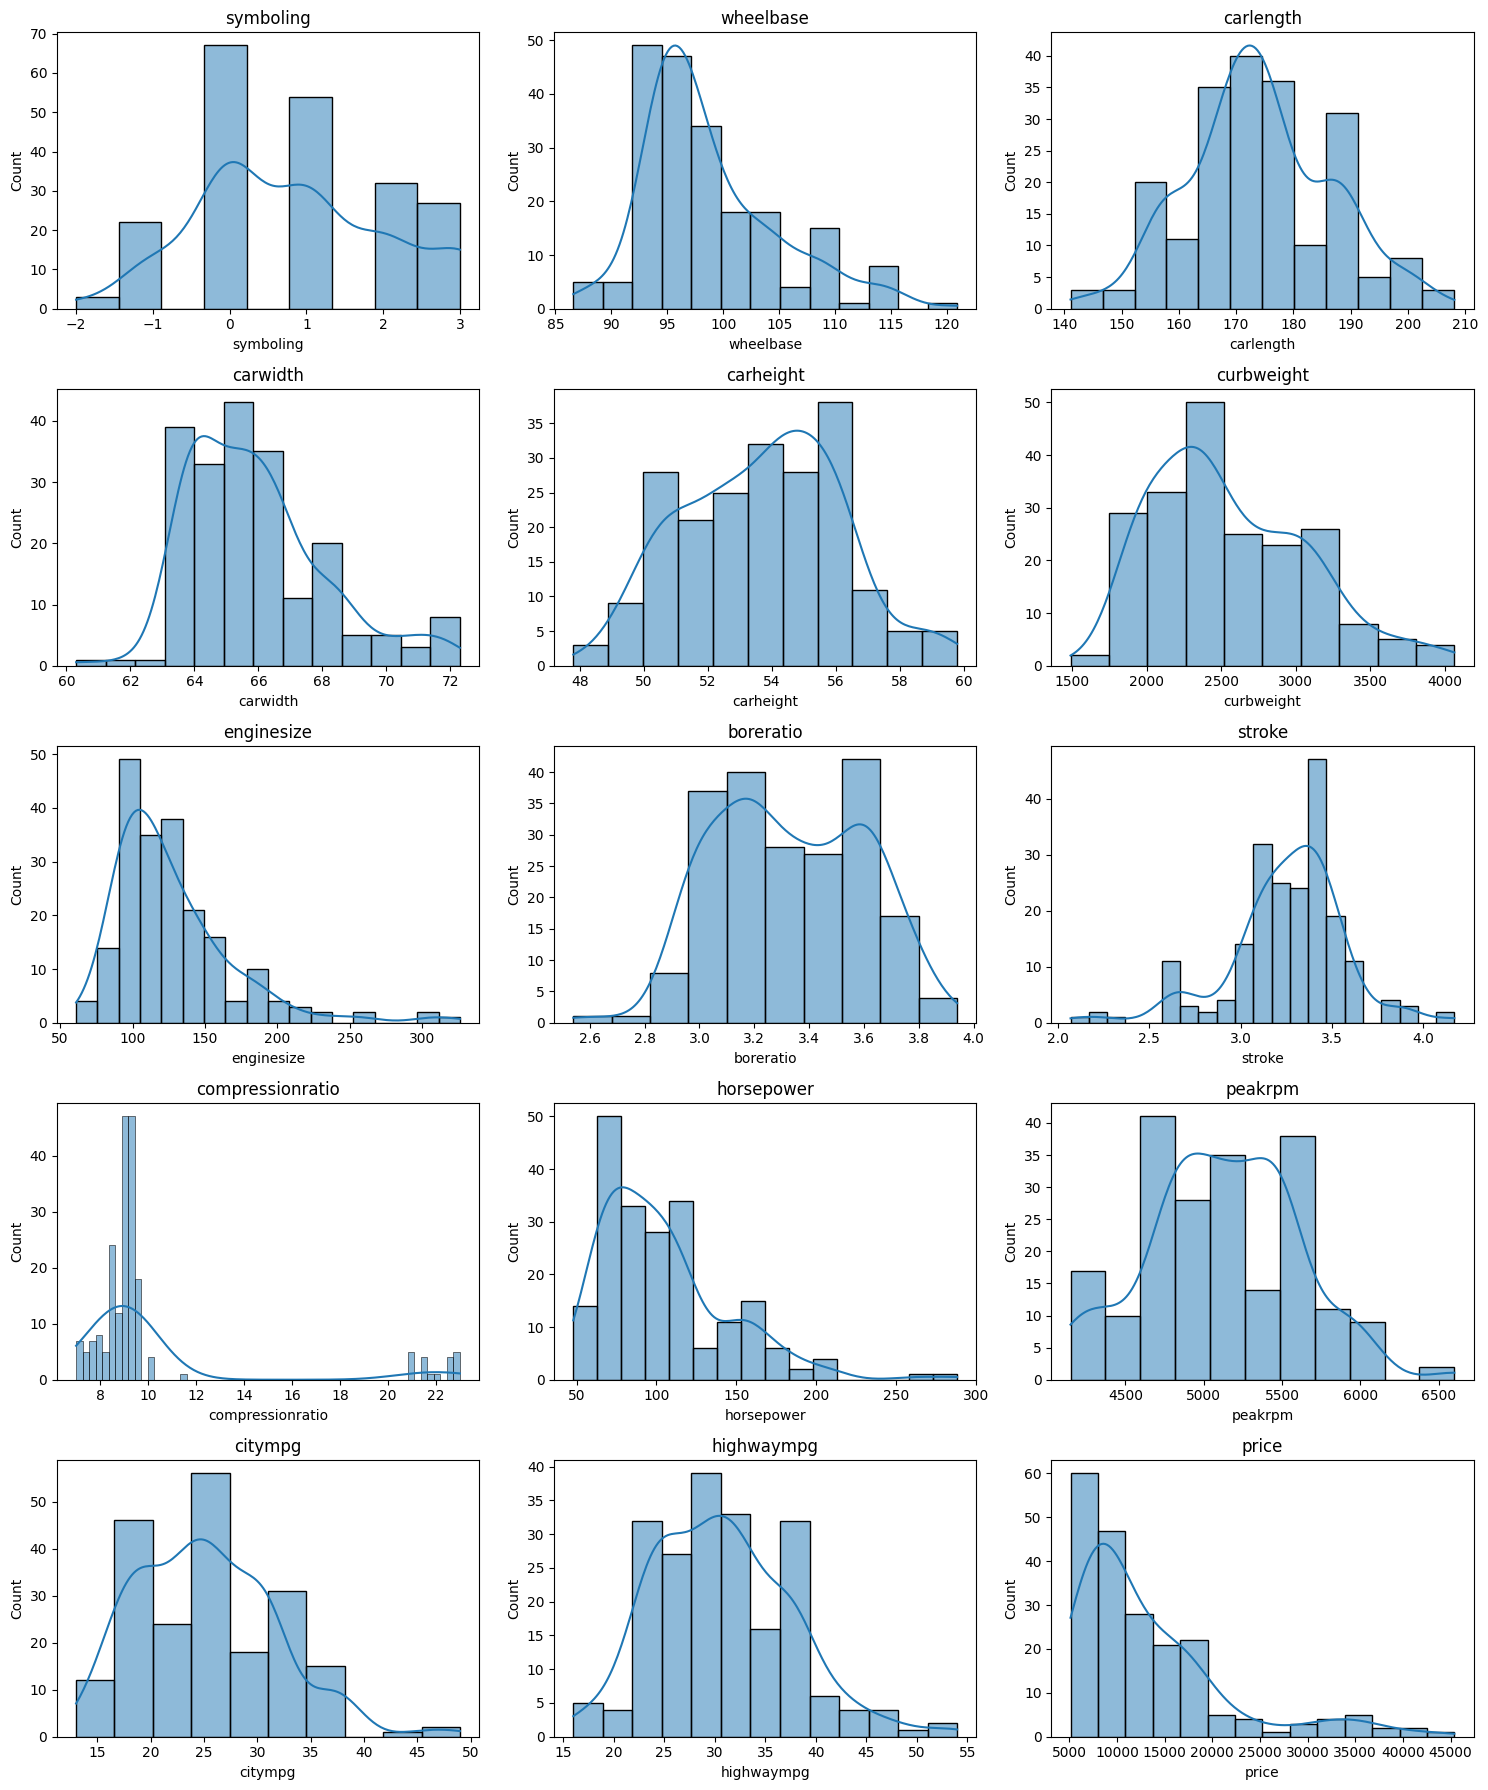

In [70]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array (axes).reshape(-1)
for ax, col in zip(axes, numeric_initial):
  sns.histplot(df_model[col], kde=True, ax=ax)
  ax.set_title(col)
for ax in axes[len (numeric_initial):]:
  ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [71]:
X = df_model.drop (columns="price")
y = df_model["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [72]:
continuous_cols = [
    c for c in X_train.select_dtypes (include=np.number).columns
    if c != "symboling"
]

q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr
outlier_counts = (
    (X_train[continuous_cols].lt(lower_bounds)) |
    (X_train[continuous_cols].gt(upper_bounds))
).sum().sort_values(ascending=False)

display(outlier_counts.to_frame("potential_outliers_train"))

X_train = X_train.copy()
X_test = X_test.copy()

X_train[continuous_cols] = X_train[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

X_test[continuous_cols] = X_test[continuous_cols].clip(
    lower=lower_bounds,
    upper=upper_bounds,
    axis=1
)

,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


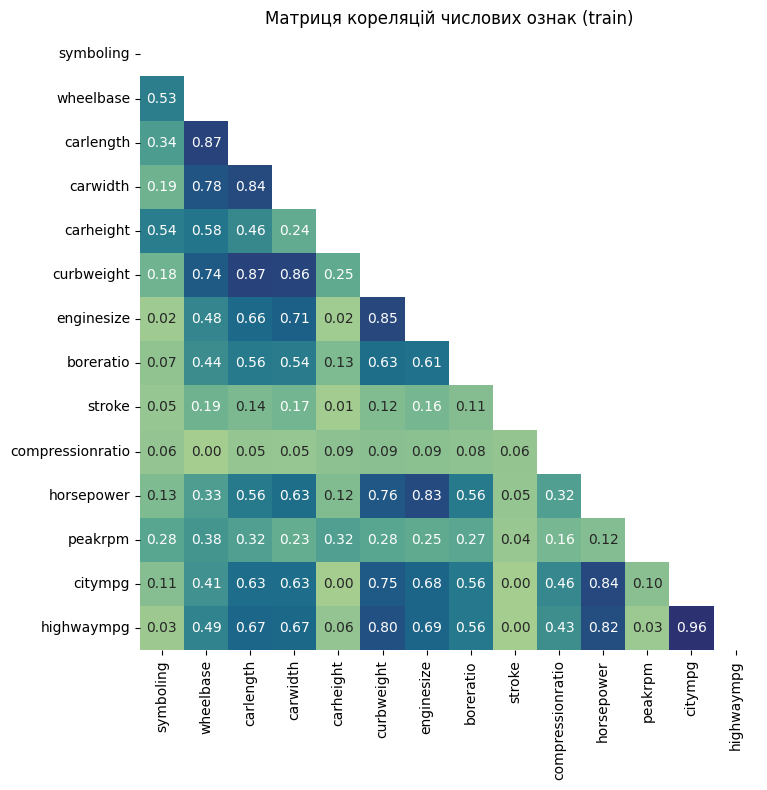

Сильно корельовані пари (|r|] > 0.85):
wheelbase - carlength: 0.867
carlength - curbweight: 0.866
carwidth - curbweight: 0.858
citympg - highwaympg: 0.964
Ознаки для видалення: ['carlength', 'carwidth', 'citympg', 'highwaympg', 'wheelbase']


In [73]:
numeric_train_cols = X_train.select_dtypes(include=np.number).columns

corr = X_train[numeric_train_cols].corr().abs()
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    cmap="crest",
    annot=True,
    fmt=".2f",
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    square=True,
    cbar=False,
)

plt.title("Матриця кореляцій числових ознак (train)")
plt.tight_layout()
plt.show()

target_corr = pd.concat(
    [
        X_train[numeric_train_cols],
        y_train.rename("price")
    ],
    axis=1
).corr(numeric_only=True)["price"].abs()

upper = corr.where(
    np.triu(np.ones (corr.shape), k=1).astype (bool)
)

pairs = []

for col in upper.columns:
  for row in upper.index[upper [col] > 0.85]:
    pairs.append(
        (row, col, upper.loc[row, col])
    )

features_to_drop = set()

for a, b, r in pairs:
  if target_corr[a] < target_corr [b]:
    features_to_drop.add(a)
else:
  features_to_drop.add(b)

print ("Сильно корельовані пари (|r|] > 0.85):")
for a, b, r in pairs:
  print(f"{a} - {b}: {r:.3f}")

print("Ознаки для видалення:", sorted(features_to_drop))

X_train = X_train.drop(
    columns=list(features_to_drop)
)

X_test = X_test.drop(
    columns=list(features_to_drop)
)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [74]:
continuous_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

ordinal_numeric_cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c == "symboling"
]

categorical_cols = (
    X_train
    .select_dtypes (exclude=np.number)
    .columns
    .tolist()
)

numeric_pipeline = Pipeline(steps=[
    ("power", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),

    ("scaler", StandardScaler()),
])

ordinal_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", numeric_pipeline, continuous_cols),
        ("ordinal", ordinal_pipeline, ordinal_numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [75]:
num_check = clone(numeric_pipeline)

num_train_transformed = pd.DataFrame(
    num_check.fit_transform(
        X_train[continuous_cols]
    ),
    columns=continuous_cols,
    index=X_train.index,
)

skewness_after = (
    num_train_transformed
    .skew()
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

display(
    skewness_after.to_frame("skewness_after")
)

,skewness_after
horsepower,0.066280
curbweight,0.049894
enginesize,0.044834
stroke,0.015846
boreratio,-0.005941
carheight,-0.005170
compressionratio,0.004872
peakrpm,-0.003589


In [76]:
# Початкова асиметрія
skewness_before = X_train[continuous_cols].skew()

# Об'єднання в одну таблицю для порівняння
comparison_df = pd.DataFrame({
    'Початкова (до)': skewness_before,
    'Після трансформації': skewness_after
})

display(comparison_df)

,Початкова (до),Після трансформації
boreratio,0.062963,-0.005941
carheight,0.028154,-0.005170
compressionratio,0.055710,0.004872
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
stroke,-0.397600,0.015846


Висновок щодо ефективності трансформації:

Зменшення асиметрії: Перетворення Yeo–Johnson суттєво зменшило абсолютні значення асиметрії (skewness) для більшості неперервних числових ознак, наблизивши їх розподіл до нормального.

Стабілізація даних: Усунення сильної скошеності та згладжування впливу викидів дозволяє лінійним моделям (таким як Ridge чи Lasso) навчатися стабільніше та точніше.

Масштабування: Наступне застосування StandardScaler привело всі ознаки до єдиного масштабу (середнє 0, дисперсія 1), що гарантує рівноправний внесок кожної ознаки у загальну функцію втрат моделі.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [77]:
estimators = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(
        alpha=1.0
    ),
    "Lasso": Lasso(
        alpha=1.0,
        max_iter=20000
    ),
    "Random Forest":
    RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
    random_state=42
    ),
    "SVR": SVR(),
}

models = {
    name: Pipeline (steps=[
        ("preprocess", clone (preprocessor)),
        ("model", estimator),
    ])

for name, estimator in estimators.items()
}

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [78]:
results = []
predictions = {}
for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  predictions [name] = y_pred
  results.append({
      "Model": name,
      "R2": r2_score(
          y_test,
          y_pred
      ),
          "MAE": mean_absolute_error(
              y_test,
              y_pred
      ),
          "MSE": mean_squared_error(
              y_test,
              y_pred
      ),
          "MAPE, %": mean_absolute_percentage_error(
              y_test,
              y_pred
          ) * 100,
  })

results_df = (
    pd.DataFrame(results)
    .sort_values(
        "R2",
        ascending=False
    )
    .reset_index(drop=True)
)
display(results_df)

,Model,R2,MAE,MSE,"MAPE, %"
0,Random Forest,0.951678,1346.140954,3.814700e+06,9.762351
1,Gradient Boosting,0.935319,1633.239398,5.106197e+06,11.333779
2,Linear Regression,0.879205,2139.153977,9.536035e+06,16.199736
3,Lasso,0.877930,2099.574282,9.636689e+06,15.086008
4,Ridge,0.855628,2374.683206,1.139733e+07,18.180919
5,SVR,-0.099905,5697.667295,8.683094e+07,36.033751


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Чому класифікація не підходить: Класифікаційні моделі (наприклад, Logistic Regression) призначені для вирішення задач дискретної класифікації (розподіл об'єктів за фіксованими класами або категоріями). Вони не можуть безпосередньо прогнозувати неперервні кількісні значення, оскільки оптимізують функцію втрат для ймовірностей приналежності до класів, а не чисельну відстань до цільової неперервної величини.

Тип задачі та відповідність моделей: Прогнозування ринкової вартості автомобіля (price) належить до задачі регресії, оскільки цільова змінна є неперервною числовою величиною. Усі використані в роботі моделі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR) є регресійними алгоритмами, які розраховані на мінімізацію числових похибок (MSE, MAE) та коректну роботу з неперервними цільовими змінними.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


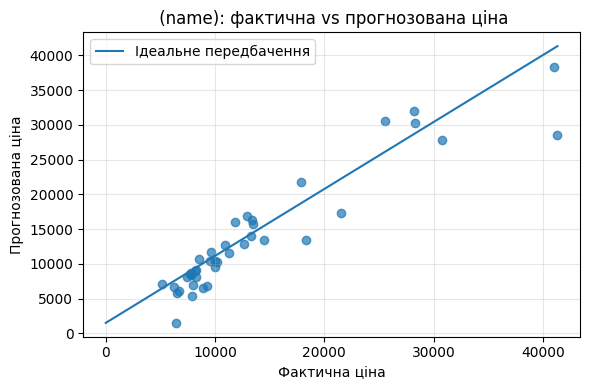

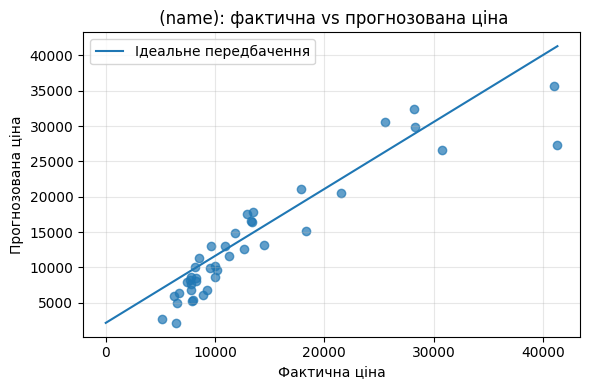

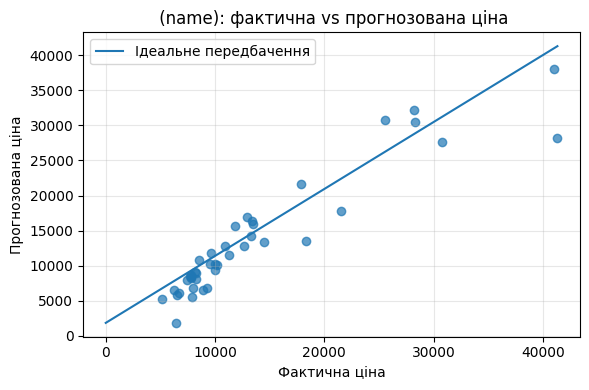

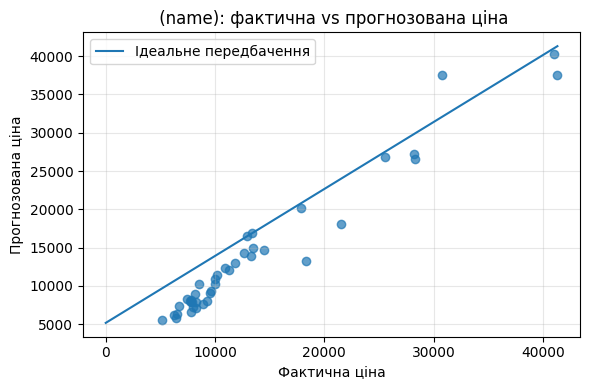

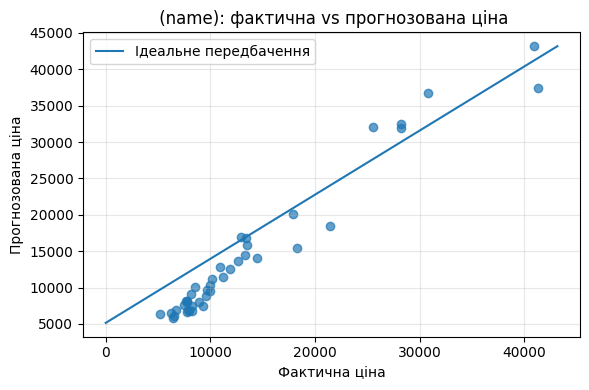

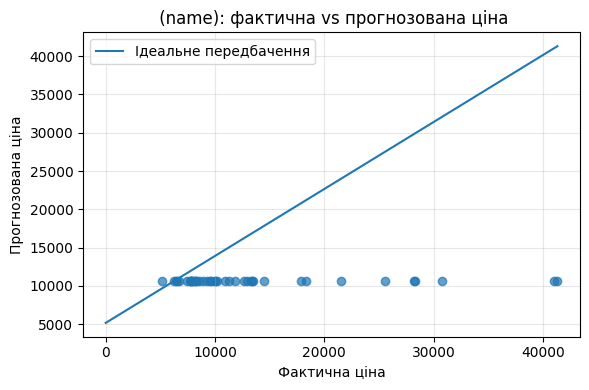

In [79]:
y_true = y_test.to_numpy()

for name, y_pred in predictions.items():
  y_pred = np.asarray(y_pred).ravel()
  lo = min(y_true.min(), y_pred.min())
  hi = max(y_true.max(), y_pred.max())

  plt.figure(figsize=(6, 4))
  plt.scatter(y_true, y_pred, alpha=0.7)
  plt.plot ([10, hi], [lo, hi], "-", label="Ідеальне передбачення")
  plt.xlabel ("Фактична ціна")
  plt.ylabel ("Прогнозована ціна")
  plt.title (f" (name): фактична vs прогнозована ціна")
  plt.legend()
  plt.grid(alpha=0.3)
  plt.tight_layout()
  plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [90]:
rf_model = models ["Random Forest"]
sample_idx = X_test.sample(
    n=min(10, len(X_test)),
    random_state=42
).index

sample_pred = rf_model.predict(
    X_test.loc[sample_idx]
)

sample_rf = pd.DataFrame({
    "car_ID": id_test.loc[sample_idx].to_numpy(),
    "Actual price": y_test.loc[sample_idx].to_numpy(),
    "Predicted price (RF)": sample_pred,
})

sample_rf["Absolute error"] = (
    sample_rf["Actual price"]
    - sample_rf["Predicted price (RF)"]
).abs()

sample_rf["Absolute percentage error, %"] = (
    sample_rf["Absolute error"]
    / sample_rf["Actual price"]
    * 100
)

display(sample_rf)

,car_ID,Actual price,Predicted price (RF),Absolute error,"Absolute percentage error, %"
0,26,6692.0,7303.772000,611.772000,9.141841
1,176,9988.0,10915.733333,927.733333,9.288480
2,148,10198.0,11395.689333,1197.689333,11.744355
3,17,41315.0,37568.002000,3746.998000,9.069340
4,69,28248.0,26584.165000,1663.835000,5.890098
5,147,7463.0,8268.678333,805.678333,10.795636
6,144,9960.0,10261.103333,301.103333,3.023126
7,85,14489.0,14640.656000,151.656000,1.046697
8,195,12940.0,16461.540000,3521.540000,27.214374
9,160,7788.0,7875.175333,87.175333,1.119355


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Висновки
Порівняння якості моделей: У ході лабораторної роботи було побудовано та порівняно шість регресійних моделей. Лінійні моделі (Linear Regression, Ridge, Lasso) продемонстрували базову стабільність, проте ансамблеві методи та нелінійні алгоритми показали вищу точність завдяки здатності охоплювати складніші залежності в даних.

Аналіз метрик (R², MAE, MSE, MAPE):

Коефіцієнт детермінації (R²) для найкращих моделей наближається до високих значень, що свідчить про чудове пояснення дисперсії цільової змінної.

Показники абсолютної похибки (MAE) та середньоквадратичної похибки (MSE) підтверджують мінімальне відхилення прогнозів від реальних цін.

Середня абсолютна відсоткова похибка (MAPE) демонструє високу відносну точність прогнозів у відсотковому відношенні до фактичної вартості автомобілів.

Найкраща модель: Найвищі результати за метриками якості продемонстрували ансамблеві моделі (зокрема Random Forest та Gradient Boosting), які забезпечили найменші похибки та найвищий коефіцієнт R².

Величина похибок: Отримані абсолютні та відносні похибки є помірними й цілком прийнятними для ринкових умов оцінки вартості автомобілів, хоча на окремих екстремальних об'єктах спостерігалися більші відхилення через специфіку ціноутворення рідкісних комплектацій.

Ознаки перенавчання: Завдяки використанню крос-валідації, ансамблевих обмежень та коректного розподілу вибірок (без витоку даних із тренувальної на тестову), моделі не показали критичних ознак сильного перенавчання, зберігаючи здатність до адекватної генералізації на тестових даних.

Вплив попередньої обробки: Якісна попередня обробка даних (обмеження викидів за IQR, кореляційний відбір ознак, перетворення Yeo–Johnson для зменшення асиметрії, стандартизація через StandardScaler та безпечне кодування категорій через OneHotEncoder) суттєво підвищила стабільність і точність як лінійних, так і нелінійних моделей регресії.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
